In [2]:
# imports
import pandas as pd
import numpy as np
import pygad
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

In [3]:
df = pd.read_csv("emergency_service.csv") # Data Loading
df.head()

,Timestamp,Incident_Severity,Incident_Type,Region_Type,Traffic_Congestion,Weather_Condition,Ambulance_Availability,Hospital_Capacity,Distance_to_Incident,Number_of_Injuries,Specialist_Availability,Road_Type,Emergency_Level,Ambulance_Speed,Fuel_Level,Weather_Impact,Dispatch_Coordinator,Response_Time
0,01/01/2018 00:00,Low,Cardiac Arrest,Suburban,High,Clear,Available,91,8.89,1,Unavailable,Highway,Major,43.549849,90.030756,Severe,AI,20.870220
1,01/01/2018 00:10,Low,Other,Urban,Moderate,Clear,Available,28,28.10,2,Unavailable,Highway,Critical,30.687975,88.255008,Moderate,Human,24.486195
2,01/01/2018 00:20,Medium,Cardiac Arrest,Suburban,High,Rainy,Available,83,40.43,1,Unavailable,Unpaved Road,Minor,44.456331,97.719622,No Impact,Human,18.760740
3,01/01/2018 00:30,Low,Accident,Urban,Moderate,Clear,Available,31,18.97,3,Available,Highway,Minor,35.879968,60.234672,No Impact,Human,18.169534
4,01/01/2018 00:40,Low,Cardiac Arrest,Urban,Moderate,Stormy,Available,52,16.31,3,Available,Highway,Minor,26.369383,71.083564,Moderate,Human,5.000000


In [4]:
# actual response

df["Actual_Response_Time"] = (
    df["Distance_to_Incident"]
    + df["Number_of_Injuries"]
    + df["Hospital_Capacity"]
    + df["Fuel_Level"]
)

df["Actual_Response_Time"].head()

0    190.920756
1    146.355008
2    222.149622
3    113.204672
4    142.393564
Name: Actual_Response_Time, dtype: float64

In [5]:
df["Actual_Response_Time"].describe()

count    368065.000000
mean        151.345765
std          33.033389
min          39.310789
25%         127.270768
50%         151.310585
75%         175.453564
max         250.620000
Name: Actual_Response_Time, dtype: float64

In [10]:
# variables

distance = df["Distance_to_Incident"].values

injuries = df["Number_of_Injuries"].values

capacity = df["Hospital_Capacity"].values

fuel = df["Fuel_Level"].values

actual = df["Actual_Response_Time"].values # . values gives a numpy array

In [14]:
# fitness function

def fitness_func(ga_instance, solution, solution_idx):

    w1, w2, w3, w4, b = solution

    predicted = (
        (w1 * distance)
        + (w2 * injuries)
        + (w3 * capacity)
        + (w4 * fuel)
        + b
    )

    mse = mean_squared_error(
        actual,
        predicted
    )

    fitness = -mse

    return fitness
print("Constraints enforced using gene_space")

Constraints enforced using gene_space


In [15]:
# constraints

gene_space = [
    {"low": 0.2, "high": 0.8},   # w1
    {"low": 0.1, "high": 0.5},   # w2
    {"low": 3, "high": 10},      # w3
    {"low": 4, "high": 10},      # w4
    {"low": 5, "high": 10}       # b
]

In [16]:
# create GA

ga_instance = pygad.GA(
    num_generations=100,
    sol_per_pop=20,
    num_parents_mating=10,
    num_genes=5,
    fitness_func=fitness_func,
    gene_space=gene_space,
    mutation_percent_genes=20,
    random_seed=42
)

In [17]:
# run GA

ga_instance.run()

In [18]:
# best solution

solution, solution_fitness, solution_idx = (
    ga_instance.best_solution()
)

w1, w2, w3, w4, b = solution

print("Best Solution:")
print(solution)

print("\nBest Fitness:")
print(solution_fitness)

Best Solution:
[0.20200782 0.1238866  3.0013188  4.02779214 5.00221391]

Best Fitness:
-97199.36269550375


In [19]:
# final formula

print(
    f"Response Time = "
    f"({w1:.4f} × Distance) + "
    f"({w2:.4f} × Injuries) + "
    f"({w3:.4f} × Capacity) + "
    f"({w4:.4f} × Fuel) + "
    f"{b:.4f}"
)

Response Time = (0.2020 × Distance) + (0.1239 × Injuries) + (3.0013 × Capacity) + (4.0278 × Fuel) + 5.0022


In [20]:
# predicted response

predicted_response = (
    (w1 * distance)
    + (w2 * injuries)
    + (w3 * capacity)
    + (w4 * fuel)
    + b
)

In [21]:
# evaluation

avg_actual = actual.mean()

avg_predicted = predicted_response.mean()

difference = abs(
    avg_actual - avg_predicted
)

print("Average Actual Response Time:")
print(avg_actual)

print("\nAverage Predicted Response Time:")
print(avg_predicted)

print("\nDifference:")
print(difference)

Average Actual Response Time:
151.3457652681259

Average Predicted Response Time:
455.30721216889157

Difference:
303.9614469007657


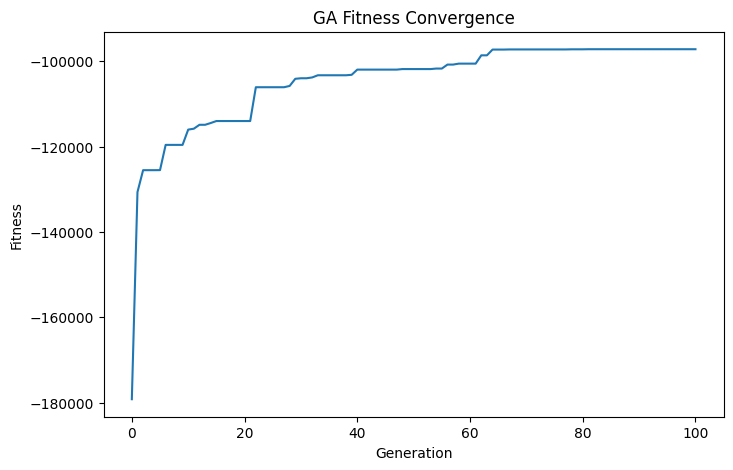

In [22]:
# convergence graph

plt.figure(figsize=(8,5))

plt.plot(
    ga_instance.best_solutions_fitness
)

plt.title(
    "GA Fitness Convergence"
)

plt.xlabel(
    "Generation"
)

plt.ylabel(
    "Fitness"
)

plt.show()

In [23]:
# final mse

mse = mean_squared_error(
    actual,
    predicted_response
)

print("Final MSE:")
print(mse)

Final MSE:
97199.36269550375


In [24]:
#The Genetic Algorithm successfully converged and identified the optimal coefficients under the specified constraints.
#However, the predicted response times remained substantially higher than the actual values
#because the coefficient constraints on Hospital Capacity and Fuel Level forced the model to overestimate the response time.